# 1.1 Getting start 
### read and process images

In [1]:
import numpy as np
import os
from skimage import io, color, transform


data_dir = "English/Img/GoodImg/Bmp"
file_dirs = {
    '4': "Sample005",
    'A': "Sample011",
    'u': "Sample057",
    'H': "Sample018"
}

images = []
labels = []

for label, directory in file_dirs.items():
    file_dir = os.path.join(data_dir, directory)
    file_lists = os.listdir(file_dir)
    #print(file_lists)
    
    for file_name in file_lists:
        img_path = os.path.join(file_dir, file_name)
        
        img = io.imread(img_path)
        img_gray = color.rgb2gray(img)
        img_resized = transform.resize(img_gray, (28, 28), mode='constant')
        #images.append(img)
        images.append(img_resized)
        labels.append(label)
    print('current length of Sample list', len(images))
print('total length of Sample list', len(images))
#print(images[0])
#print(labels)
#plt.imshow(images[1],cmap=plt.cm.gray)

current length of Sample list 47
current length of Sample list 605
current length of Sample list 646
current length of Sample list 839
total length of Sample list 839


In [2]:
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt

newimages = np.array(images)
newlabels = np.array(labels)
print(newimages.shape)
print(newlabels.shape)


(839, 28, 28)
(839,)


In [3]:
# reduced from 3-dimension to a two-dimensional matrix(number of images, (length*width)
newimages = np.reshape(newimages,(839,(28*28)))
print(newimages.shape)
print('Data size: {0} x {1} and label size {2}'.format(newimages.shape[0],newimages.shape[1],newlabels.shape[0]))


(839, 784)
Data size: 839 x 784 and label size 839


# part two: binary classifier

### train/validation/test set

1. shuffle the index of data ('4','A') into random sequence,reorganize the data according to this random sequence
2. Then split 605 numbers of data set into 3 parts, 363 of training data, 121 of validate data, 121 of test data, the three sets of data weight is almost 3:1:1.

In [4]:
from sklearn.model_selection import train_test_split


#random and split the data into train and test sets
#shuffle the dataindex
shuffle_index = np.random.permutation(605)

# use 363 samples as training and 121 as test
# train: validate: test   8:1:1
X = newimages[:605][shuffle_index[:]]
Y = newlabels[:605][shuffle_index[:]]

x_train, x_other, y_train, y_other = train_test_split(X , Y ,test_size=0.4, random_state = 11)
#X[:484], X[484:], Y[:484], Y[484:]

x_val, x_test,  y_val, y_test = train_test_split(x_other, y_other, test_size=0.5, random_state = 11)
#x_other[:60], x_other[60:], y_other[:60],y_other[60:]


#print(y_train)
print('length of train data', len(x_train))
print('length of validation data', len(x_val))
print('length of test data', len(x_test))

length of train data 363
length of validation data 121
length of test data 121


We create new labels which are true meaning we have a 4

In [5]:
y_train_4 = (y_train == '4')
y_val_4 = (y_val == '4')
y_test_4 = (y_test == '4')
#print(y_test_4)
print('We have a training set with {0} images of 4, a validate set with {1}, a test set with {2}'.format(sum(y_train_4),sum(y_val_4),sum(y_test_4)))

We have a training set with 27 images of 4, a validate set with 13, a test set with 7


In [6]:
from sklearn.linear_model import SGDClassifier
from sklearn.linear_model import LogisticRegression

bin_clf = LogisticRegression(max_iter= 10, tol=0.1, solver='liblinear')  
#sgd_clf = SGDClassifier(max_iter=5, random_state=42)
bin_clf.fit(x_train,y_train_4)
y_pred_train = bin_clf.predict(x_train)
y_pred_test = bin_clf.predict(x_test)

calculate the accuracy

In [7]:
x_train.shape, y_train.shape, y_pred_train.shape,y_pred_test.shape

((363, 784), (363,), (363,), (121,))

In [8]:
print('Classifier accuracy on the training set is {0} '.format(sum(y_pred_train == y_train_4)/y_pred_train.shape))
print('Classifier accuracy on the test set is {0} '.format(sum(y_pred_test == y_test_4)/y_pred_test.shape))

Classifier accuracy on the training set is [0.96418733] 
Classifier accuracy on the test set is [0.98347107] 


pick a 4 out of the training set and see what the classifier predicts.

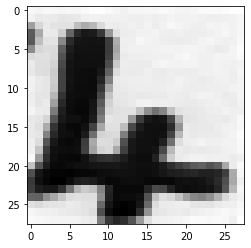

Classifier prediction is [ True] that the image is a 4


In [9]:
np.random.seed(50)
index4 = np.where(y_train== '4')[0]
# randomly pick an image again
pick = index4[np.random.choice(index4.shape[0])]
img_4 = x_train[pick,:]
# reshape into a matrix
img_4_re = img_4.reshape(28, 28)
plt.imshow(img_4_re, cmap = matplotlib.cm.binary,
           interpolation="nearest")
# plt.axis("on")
plt.show()

print('Classifier prediction is {0} that the image is a 4'.format(bin_clf.predict([img_4])))

### confusion matrix, accuracy, precision, recall

In [10]:
from sklearn.metrics import confusion_matrix,precision_score

cm_train = confusion_matrix(y_train_4, y_pred_train,labels=[1,0])
print( 'the confusion matrix: \n {0}'.format(cm_train))
cm_test = confusion_matrix(y_test_4, y_pred_test,labels=[1,0])
print( 'the confusion matrix: \n {0}'.format(cm_test))

the confusion matrix: 
 [[ 14  13]
 [  0 336]]
the confusion matrix: 
 [[  5   2]
 [  0 114]]


In [11]:
def scores(cm):
    tp,fn,fp,tn= cm.ravel()

    accuracy = (tp + tn) / (tp + tn + fp + fn)
    recall = tp / (tp + fn)
    precision = tp / (tp + fp)
    f1 = 2 * recall * precision/( recall + precision )
    print("accuracy:",accuracy)
    print("precision:",precision)
    print("recall:",recall)
    print("f1:", f1)

print("training set:")
scores(cm_train)
print("\ntesting set:")
scores(cm_test)

training set:
accuracy: 0.9641873278236914
precision: 1.0
recall: 0.5185185185185185
f1: 0.6829268292682926

testing set:
accuracy: 0.9834710743801653
precision: 1.0
recall: 0.7142857142857143
f1: 0.8333333333333333


verify the accuracy, precision, recall respectively using scikit-learn function

In [12]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, accuracy_score
def verify(y_train, y_pred):
    acc = accuracy_score(y_train, y_pred)
    pre = precision_score(y_train, y_pred)
    rec = recall_score(y_train, y_pred, pos_label=1)
    f1 = f1_score(y_train, y_pred)
    print("accuracy:", acc)
    print('precision', pre)
    print('recall:',rec)
    print("f1:", f1)
    
print("verify the scores : example training set")
verify(y_train_4,y_pred_train)


verify the scores : example training set
accuracy: 0.9641873278236914
precision 1.0
recall: 0.5185185185185185
f1: 0.6829268292682926


### print ROC curve

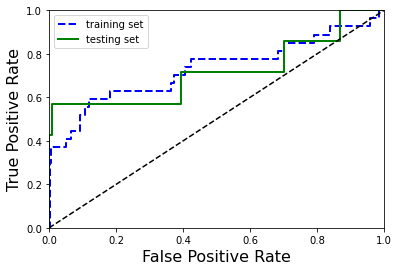

In [13]:
from sklearn.model_selection import cross_val_predict  
from sklearn.metrics import roc_curve, precision_recall_curve

def plot_roc_curve(fpr_train, tpr_train, fpr_test, tpr_test):
    plt.plot(fpr_train, tpr_train, "b--", linewidth=2, label="training set")
    plt.plot(fpr_test, tpr_test, "g-", linewidth=2, label="testing set")
    plt.legend()
    plt.plot([0, 1], [0, 1], 'k--')
    plt.axis([0, 1, 0, 1])
    plt.xlabel('False Positive Rate', fontsize=16)
    plt.ylabel('True Positive Rate', fontsize=16)

def fpr_tpr(bin_clf, x, y):
    y_scores = cross_val_predict(bin_clf, x, y,cv=5, method="decision_function")
    #precisions, recalls, thresholds = precision_recall_curve(y_train_4, y_scores) 
    fpr, tpr, thresholds = roc_curve(y , y_scores)
    return fpr, tpr
fpr_train, tpr_train = fpr_tpr(bin_clf, x_train, y_train_4)
fpr_test, tpr_test = fpr_tpr(bin_clf, x_test, y_test_4)
plot_roc_curve(fpr_train, tpr_train, fpr_test, tpr_test)
plt.show()

### analyse results:

# 1.3 Multiclass classifier

## 1.3.1 One-VS-One

1. shuffle index of whole data into random sequence, reorganize the data according to this random sequence
2. stratified sampling to ensure the same proportion as original data--- split 839 numbers of data set to make sure data weight is almost 3:1:1. 
3. output the number of any label in three sets to see whether the proportation is same as original dataset.

In [14]:
from sklearn.model_selection import train_test_split

#shuffle the dataindex 
shuffle_index = np.random.permutation(839)
X2 = newimages[shuffle_index[:]]
Y2 = newlabels[shuffle_index[:]]

# train: validate: test = [8:1:1]
x_train2, x_other2, y_train2, y_other2 = train_test_split(X2,Y2,test_size=0.3,stratify = Y2) 
#ensure the same proportion as original data
x_val2, x_test2,  y_val2, y_test2 = train_test_split(x_other2,y_other2, test_size=0.5, stratify = y_other2)
print('length of train data', len(y_train2))
print('length of validation data', len(y_val2))
print('length of test data', len(y_test2))

length of train data 587
length of validation data 126
length of test data 126


In [15]:
y_train_4 = (y_train2 == 'u')
y_val_4 = (y_val2 == 'u')
y_test_4 = (y_test2 == 'u')

print('now, image numbers of u in training set is {0}, in validate set is {1}, in test set is {2}'.format(sum(y_train_4),sum(y_val_4),sum(y_test_4)))

now, image numbers of u in training set is 29, in validate set is 6, in test set is 6


### confusion matrix, accuracy, precision, recall

using logisticregression for oneVSone classifier, "newton-cg" as solver, 10 iterations.

In [16]:
from sklearn.multiclass import OneVsOneClassifier
from sklearn.linear_model import LogisticRegression

#multi_class ='ovr’// ‘multinomial-- cannot use liblinear’
lg = LogisticRegression(multi_class='multinomial', solver='newton-cg', max_iter=10, class_weight = None, random_state =42)
ovo_clf = OneVsOneClassifier(lg).fit(x_train2, y_train2)
#ovo_clf = OneVsOneClassifier(LinearSVC(random_state=0)).fit(x_train2, y_train2)
y_pred2_train = ovo_clf.predict(x_train2)
y_pred2_test = ovo_clf.predict(x_test2)

def dataset(y_train,y_pred):
    
    conf_mx = confusion_matrix(y_train, y_pred,labels=['4','A','u','H'])
    print('Confusion matrix: \n{0}'.format(conf_mx))

    accuracy = np.sum(conf_mx.diagonal())/np.sum(conf_mx)
    precision = conf_mx.diagonal()/np.sum(conf_mx,axis=0) #sum column 
    recall = conf_mx.diagonal()/np.sum(conf_mx,axis=1) #sum row
    print("precision of each class is",precision)
    print("recall of each class is",recall)

    ave_pre = sum(precision)/len(precision)
    ave_rc = sum(recall)/len(recall)
    f1 = (2 * ave_pre * ave_rc )/( ave_pre + ave_rc )

    print("accuracy:",accuracy)
    print("average precision:",ave_pre)
    print("average recall:",ave_rc)
    print("f1:", f1)

print("training set:")
dataset(y_train2,y_pred2_train)
print("\ntesting set:")
dataset(y_test2,y_pred2_test)

training set:
Confusion matrix: 
[[ 19  13   0   1]
 [  0 383   0   7]
 [  0  10  17   2]
 [  0  58   0  77]]
precision of each class is [1.         0.82543103 1.         0.88505747]
recall of each class is [0.57575758 0.98205128 0.5862069  0.57037037]
accuracy: 0.8449744463373083
average precision: 0.9276221264367817
average recall: 0.6785965311827381
f1: 0.7838050619848627

testing set:
Confusion matrix: 
[[ 1  4  0  2]
 [ 1 74  1  8]
 [ 0  4  1  1]
 [ 0 20  1  8]]
precision of each class is [0.5        0.7254902  0.33333333 0.42105263]
recall of each class is [0.14285714 0.88095238 0.16666667 0.27586207]
accuracy: 0.6666666666666666
average precision: 0.494969040247678
average recall: 0.3665845648604269
f1: 0.4212111914169535


/Users/liulingjia/opt/anaconda3/lib/python3.9/site-packages/sklearn/utils/optimize.py:210: ConvergenceWarning: newton-cg failed to converge. Increase the number of iterations.
  warnings.warn(
/Users/liulingjia/opt/anaconda3/lib/python3.9/site-packages/sklearn/utils/optimize.py:210: ConvergenceWarning: newton-cg failed to converge. Increase the number of iterations.
  warnings.warn(
/Users/liulingjia/opt/anaconda3/lib/python3.9/site-packages/sklearn/utils/optimize.py:210: ConvergenceWarning: newton-cg failed to converge. Increase the number of iterations.
  warnings.warn(
/Users/liulingjia/opt/anaconda3/lib/python3.9/site-packages/sklearn/utils/optimize.py:210: ConvergenceWarning: newton-cg failed to converge. Increase the number of iterations.
  warnings.warn(
/Users/liulingjia/opt/anaconda3/lib/python3.9/site-packages/sklearn/utils/optimize.py:210: ConvergenceWarning: newton-cg failed to converge. Increase the number of iterations.
  warnings.warn(
/Users/liulingjia/opt/anaconda3/lib

increase the train iteration to 100

In [17]:
from sklearn.multiclass import OneVsOneClassifier
from sklearn.linear_model import LogisticRegression

#multi_class ='ovr’// ‘multinomial-- cannot use liblinear’
lg = LogisticRegression(multi_class='multinomial', solver='newton-cg', max_iter=100, class_weight = None, random_state =42)
ovo_clf = OneVsOneClassifier(lg).fit(x_train2, y_train2)

y_pred2_train = ovo_clf.predict(x_train2)
y_pred2_test = ovo_clf.predict(x_test2)

def dataset(y_train,y_pred):
    
    conf_mx = confusion_matrix(y_train, y_pred,labels=['4','A','u','H'])
    print('Confusion matrix: \n{0}'.format(conf_mx))

    accuracy = np.sum(conf_mx.diagonal())/np.sum(conf_mx)
    precision = conf_mx.diagonal()/np.sum(conf_mx,axis=0) #sum column 
    recall = conf_mx.diagonal()/np.sum(conf_mx,axis=1) #sum row
    print("precision of each class is",precision)
    print("recall of each class is",recall)

    ave_pre = sum(precision)/len(precision)
    ave_rc = sum(recall)/len(recall)
    f1 = (2 * ave_pre * ave_rc )/( ave_pre + ave_rc )

    print("accuracy:",accuracy)
    print("average precision:",ave_pre)
    print("average recall:",ave_rc)
    print("f1:", f1)

print("training set:")
dataset(y_train2,y_pred2_train)
print("\ntesting set:")
dataset(y_test2,y_pred2_test)


training set:
Confusion matrix: 
[[ 22   9   0   2]
 [  0 388   0   2]
 [  0   8  21   0]
 [  0  43   0  92]]
precision of each class is [1.         0.86607143 1.         0.95833333]
recall of each class is [0.66666667 0.99487179 0.72413793 0.68148148]
accuracy: 0.8909710391822828
average precision: 0.9561011904761906
average recall: 0.7667894685136064
f1: 0.8510445162205806

testing set:
Confusion matrix: 
[[ 2  4  0  1]
 [ 1 73  0 10]
 [ 1  3  1  1]
 [ 0 17  3  9]]
precision of each class is [0.5        0.75257732 0.25       0.42857143]
recall of each class is [0.28571429 0.86904762 0.16666667 0.31034483]
accuracy: 0.6746031746031746
average precision: 0.48278718703976436
average recall: 0.40794334975369456
f1: 0.44222088311503194


verify the accuracy, precision, recall respectively using scikit-learn function

In [18]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, accuracy_score
    
print("verify the scores : example training set")
accuracy_score2 = accuracy_score(y_train2, y_pred2_train)
precision_score2 = precision_score(y_train2, y_pred2_train,average='macro')
recall_score2 = recall_score(y_train2, y_pred2_train, average='macro')

print("accuracy:", accuracy_score2)
print('average precision', precision_score2)
print('average recall:',recall_score2)


verify the scores : example training set
accuracy: 0.8909710391822828
average precision 0.9561011904761905
average recall: 0.7667894685136064


the same procedure works with LinearSVC, SGDclassifier to see the  acc/pre/recall each other.

In [19]:
from sklearn.multiclass import OneVsOneClassifier
from sklearn.svm import LinearSVC

ovo_clf = OneVsOneClassifier(LinearSVC(random_state=0)).fit(x_train2, y_train2)
y_pred2_train = ovo_clf.predict(x_train2)
y_pred2_test = ovo_clf.predict(x_test2)

def dataset(y_train,y_pred):
    
    conf_mx = confusion_matrix(y_train, y_pred,labels=['4','A','u','H'])
    print('Confusion matrix: \n{0}'.format(conf_mx))

    accuracy = np.sum(conf_mx.diagonal())/np.sum(conf_mx)
    precision = conf_mx.diagonal()/np.sum(conf_mx,axis=0) #sum column 
    recall = conf_mx.diagonal()/np.sum(conf_mx,axis=1) #sum row
    print("precision of each class is",precision)
    print("recall of each class is",recall)

    ave_pre = sum(precision)/len(precision)
    ave_rc = sum(recall)/len(recall)
    f1 = (2 * ave_pre * ave_rc )/( ave_pre + ave_rc )

    print("accuracy:",accuracy)
    print("average precision:",ave_pre)
    print("average recall:",ave_rc)
    print("f1:", f1)

print("training set:")
dataset(y_train2,y_pred2_train)
print("\ntesting set:")
dataset(y_test2,y_pred2_test)

/Users/liulingjia/opt/anaconda3/lib/python3.9/site-packages/sklearn/svm/_base.py:1206: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/liulingjia/opt/anaconda3/lib/python3.9/site-packages/sklearn/svm/_base.py:1206: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/liulingjia/opt/anaconda3/lib/python3.9/site-packages/sklearn/svm/_base.py:1206: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/liulingjia/opt/anaconda3/lib/python3.9/site-packages/sklearn/svm/_base.py:1206: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


training set:
Confusion matrix: 
[[ 32   1   0   0]
 [  0 390   0   0]
 [  0   2  27   0]
 [  0  26   0 109]]
precision of each class is [1.         0.93078759 1.         1.        ]
recall of each class is [0.96969697 1.         0.93103448 0.80740741]
accuracy: 0.9505962521294719
average precision: 0.9826968973747017
average recall: 0.9270347149657494
f1: 0.9540546245019464

testing set:
Confusion matrix: 
[[ 3  2  0  2]
 [ 0 70  0 14]
 [ 0  3  2  1]
 [ 0 12  6 11]]
precision of each class is [1.         0.8045977  0.25       0.39285714]
recall of each class is [0.42857143 0.83333333 0.33333333 0.37931034]
accuracy: 0.6825396825396826
average precision: 0.611863711001642
average recall: 0.4936371100164203
f1: 0.5464286019156884


/Users/liulingjia/opt/anaconda3/lib/python3.9/site-packages/sklearn/svm/_base.py:1206: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/liulingjia/opt/anaconda3/lib/python3.9/site-packages/sklearn/svm/_base.py:1206: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


oneVsone classifier: works with SGDclassifier, change the hyperparameters:

In [20]:
from sklearn.multiclass import OneVsOneClassifier
from sklearn.linear_model import SGDClassifier

#sgd_clf = SGDClassifier(loss= 'log', alpha=0.001, max_iter=10, random_state=42, learning_rate = 'optimal')
sgd_clf = SGDClassifier(loss= 'log', alpha=0.001, max_iter=100, random_state=42, learning_rate = 'optimal')
#sgd_clf = SGDClassifier(loss= 'log', alpha=0.0001, max_iter=100, random_state=42, learning_rate = 'optimal')
ovo_clf = OneVsOneClassifier(sgd_clf).fit(x_train2, y_train2)
y_pred2_train = ovo_clf.predict(x_train2)
y_pred2_test = ovo_clf.predict(x_test2)

def dataset(y_train,y_pred):
    
    conf_mx = confusion_matrix(y_train, y_pred,labels=['4','A','u','H'])
    print('Confusion matrix: \n{0}'.format(conf_mx))

    accuracy = np.sum(conf_mx.diagonal())/np.sum(conf_mx)
    precision = conf_mx.diagonal()/np.sum(conf_mx,axis=0) #sum column 
    recall = conf_mx.diagonal()/np.sum(conf_mx,axis=1) #sum row
    print("precision of each class is",precision)
    print("recall of each class is",recall)

    ave_pre = sum(precision)/len(precision)
    ave_rc = sum(recall)/len(recall)
    f1 = (2 * ave_pre * ave_rc )/( ave_pre + ave_rc )

    print("accuracy:",accuracy)
    print("average precision:",ave_pre)
    print("average recall:",ave_rc)
    print("f1:", f1)

print("training set:")
dataset(y_train2,y_pred2_train)
print("\ntesting set:")
dataset(y_test2,y_pred2_test)

training set:
Confusion matrix: 
[[ 14  18   0   1]
 [  0 390   0   0]
 [  1  14  11   3]
 [  0  90   0  45]]
precision of each class is [0.93333333 0.76171875 1.         0.91836735]
recall of each class is [0.42424242 1.         0.37931034 0.33333333]
accuracy: 0.7836456558773425
average precision: 0.9033548575680272
average recall: 0.534221525600836
f1: 0.6713961300687705

testing set:
Confusion matrix: 
[[ 0  6  0  1]
 [ 1 78  0  5]
 [ 0  5  1  0]
 [ 0 24  1  4]]
precision of each class is [0.         0.69026549 0.5        0.4       ]
recall of each class is [0.         0.92857143 0.16666667 0.13793103]
accuracy: 0.6587301587301587
average precision: 0.39756637168141595
average recall: 0.3082922824302135
f1: 0.3472838178839663


In [21]:
from sklearn.multiclass import OneVsOneClassifier
from sklearn.linear_model import SGDClassifier

sgd_clf = SGDClassifier(loss= 'log', alpha=0.001, max_iter=50, random_state=42, learning_rate = 'optimal')
#sgd_clf = SGDClassifier(loss= 'log', alpha=0.001, max_iter=100, random_state=42, learning_rate = 'optimal')
ovo_clf = OneVsOneClassifier(sgd_clf).fit(x_train2, y_train2)
y_pred2_train = ovo_clf.predict(x_train2)
y_pred2_test = ovo_clf.predict(x_test2)

def dataset(y_train,y_pred):
    
    conf_mx = confusion_matrix(y_train, y_pred,labels=['4','A','u','H'])
    print('Confusion matrix: \n{0}'.format(conf_mx))

    accuracy = np.sum(conf_mx.diagonal())/np.sum(conf_mx)
    precision = conf_mx.diagonal()/np.sum(conf_mx,axis=0) #sum column 
    recall = conf_mx.diagonal()/np.sum(conf_mx,axis=1) #sum row
    print("precision of each class is",precision)
    print("recall of each class is",recall)

    ave_pre = sum(precision)/len(precision)
    ave_rc = sum(recall)/len(recall)
    f1 = (2 * ave_pre * ave_rc )/( ave_pre + ave_rc )

    print("accuracy:",accuracy)
    print("average precision:",ave_pre)
    print("average recall:",ave_rc)
    print("f1:", f1)

print("training set:")
dataset(y_train2,y_pred2_train)
print("\ntesting set:")
dataset(y_test2,y_pred2_test)

training set:
Confusion matrix: 
[[ 15   9   0   9]
 [  0 309   0  81]
 [  1   9  12   7]
 [  0  22   0 113]]
precision of each class is [0.9375     0.88538682 1.         0.53809524]
recall of each class is [0.45454545 0.79230769 0.4137931  0.83703704]
accuracy: 0.7649063032367973
average precision: 0.8402455143948697
average recall: 0.6244208218346149
f1: 0.7164318338768568

testing set:
Confusion matrix: 
[[ 1  1  0  5]
 [ 1 57  0 26]
 [ 0  3  1  2]
 [ 0 14  1 14]]
precision of each class is [0.5        0.76       0.5        0.29787234]
recall of each class is [0.14285714 0.67857143 0.16666667 0.48275862]
accuracy: 0.5793650793650794
average precision: 0.514468085106383
average recall: 0.3677134646962233
f1: 0.4288841499630752


/Users/liulingjia/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_stochastic_gradient.py:696: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


In [22]:
from sklearn.multiclass import OneVsOneClassifier
from sklearn.linear_model import SGDClassifier

#sgd_clf = SGDClassifier(loss= 'log', alpha=0.001, max_iter=100, random_state=42, learning_rate = 'optimal')
sgd_clf = SGDClassifier(loss= 'log', alpha=0.0001, max_iter=100, random_state=42, learning_rate = 'optimal')
ovo_clf = OneVsOneClassifier(sgd_clf).fit(x_train2, y_train2)
y_pred2_train = ovo_clf.predict(x_train2)
y_pred2_test = ovo_clf.predict(x_test2)

def dataset(y_train,y_pred):
    
    conf_mx = confusion_matrix(y_train, y_pred,labels=['4','A','u','H'])
    print('Confusion matrix: \n{0}'.format(conf_mx))

    accuracy = np.sum(conf_mx.diagonal())/np.sum(conf_mx)
    precision = conf_mx.diagonal()/np.sum(conf_mx,axis=0) #sum column 
    recall = conf_mx.diagonal()/np.sum(conf_mx,axis=1) #sum row
    print("precision of each class is",precision)
    print("recall of each class is",recall)

    ave_pre = sum(precision)/len(precision)
    ave_rc = sum(recall)/len(recall)
    f1 = (2 * ave_pre * ave_rc )/( ave_pre + ave_rc )

    print("accuracy:",accuracy)
    print("average precision:",ave_pre)
    print("average recall:",ave_rc)
    print("f1:", f1)

print("training set:")
dataset(y_train2,y_pred2_train)
print("\ntesting set:")
dataset(y_test2,y_pred2_test)

training set:
Confusion matrix: 
[[ 22   8   0   3]
 [  2 326  20  42]
 [  0   5  22   2]
 [  0  31   4 100]]
precision of each class is [0.91666667 0.88108108 0.47826087 0.68027211]
recall of each class is [0.66666667 0.83589744 0.75862069 0.74074074]
accuracy: 0.8006814310051107
average precision: 0.7390701815391256
average recall: 0.7504813832400039
f1: 0.7447320727499198

testing set:
Confusion matrix: 
[[ 2  2  1  2]
 [ 1 62  7 14]
 [ 0  2  4  0]
 [ 1 11  5 12]]
precision of each class is [0.5        0.80519481 0.23529412 0.42857143]
recall of each class is [0.28571429 0.73809524 0.66666667 0.4137931 ]
accuracy: 0.6349206349206349
average precision: 0.4922650878533232
average recall: 0.5260673234811165
f1: 0.5086051947827978


### analyse results:

## One-VS-All
###  not deal with imbalance data.  VS  deal with imbalanced data using smote

not deal with imbalance data: 
1. shuffle index of whole data into random sequence, reorganize the data according to this random sequence.
2. stratified sampling to ensure the same proportion as original data--- split 839 numbers of data set to make sure data weight is almost 3:1:1. 

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.multiclass import OneVsRestClassifier

#random and split the data into train and test sets
#shuffle the dataindex
shuffle_index = np.random.permutation(839)

# train: validate: test = [3:1:1]
X3 = newimages[shuffle_index[:]]
Y3 = newlabels[shuffle_index[:]]

x_train3, x_other3, y_train3, y_other3 = train_test_split(X3,Y3,test_size=0.3,stratify = Y3)
#= train_test_split(X,Y,test_size=0.4, random_state = 11)

x_val3, x_test3,  y_val3, y_test3 = train_test_split(x_other3,y_other3, test_size=0.5, stratify = y_other3)
#train_test_split(x_other,y_other,test_size=0.5, random_state = 11)

#print(y_train2)
print('length of train data', len(x_train3))
print('length of validation data', len(x_val3))
print('length of test data', len(x_test3))

lg2 = LogisticRegression(multi_class='ovr', solver='newton-cg', max_iter=100, class_weight = None, random_state =42)

ova_clf = OneVsRestClassifier(lg2)

#ova_clf = OneVsRestClassifier(LinearSVC(random_state=0))
ova_clf.fit(x_train3, y_train3)
y_pred3_train = ova_clf.predict(x_train3)
y_pred3_test = ova_clf.predict(x_test3)


def dataset(y_train,y_pred):
    
    conf_mx = confusion_matrix(y_train, y_pred,labels=['4','A','u','H'])
    print('Confusion matrix: \n{0}'.format(conf_mx))

    accuracy = np.sum(conf_mx.diagonal())/np.sum(conf_mx)
    precision = conf_mx.diagonal()/np.sum(conf_mx,axis=0) #sum column 
    recall = conf_mx.diagonal()/np.sum(conf_mx,axis=1) #sum row
    print("precision of each class is",precision)
    print("recall of each class is",recall)

    ave_pre = sum(precision)/len(precision)
    ave_rc = sum(recall)/len(recall)
    f1 = (2 * ave_pre * ave_rc )/( ave_pre + ave_rc )

    print("accuracy:",accuracy)
    print("average precision:",ave_pre)
    print("average recall:",ave_rc)
    print("f1:", f1)

print("training set:")
dataset(y_train3,y_pred3_train)
print("\ntesting set:")
dataset(y_test3,y_pred3_test)

length of train data 587
length of validation data 126
length of test data 126
training set:
Confusion matrix: 
[[ 18  12   0   3]
 [  0 387   0   3]
 [  0  11  17   1]
 [  0  62   0  73]]
precision of each class is [1.         0.81991525 1.         0.9125    ]
recall of each class is [0.54545455 0.99230769 0.5862069  0.54074074]
accuracy: 0.8432708688245315
average precision: 0.933103813559322
average recall: 0.6661774687636757
f1: 0.7773651120430463

testing set:
Confusion matrix: 
[[ 1  5  0  1]
 [ 0 76  0  8]
 [ 1  5  0  0]
 [ 0 16  1 12]]
precision of each class is [0.5        0.74509804 0.         0.57142857]
recall of each class is [0.14285714 0.9047619  0.         0.4137931 ]
accuracy: 0.7063492063492064
average precision: 0.4541316526610644
average recall: 0.36535303776683087
f1: 0.40493344362334976


verify the accuracy, precision, recall respectively using scikit-learn function

In [24]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, accuracy_score
print("verify the scores : example training set")
accuracy_score3 = accuracy_score(y_train3, y_pred3_train)
precision_score3 = precision_score(y_train3, y_pred3_train,average='macro')
recall_score3 = recall_score(y_train3, y_pred3_train, average='macro')

print("accuracy:", accuracy_score3)
print('average precision', precision_score3)
print('average recall:',recall_score3)

verify the scores : example training set
accuracy: 0.8432708688245315
average precision 0.933103813559322
average recall: 0.6661774687636757


deal with imbalanced data:

1. using smote making a balanced data proportaion
2. shuffle index of whole data into random sequence, reorganize the data according to this random sequence.
3. stratified sampling to ensure the same proportion as original data--- split the smoted numbers of data set to make sure data weight is almost 8:1:1. 

In [25]:
from imblearn.over_sampling import SMOTE
from collections import Counter 
from sklearn.model_selection import train_test_split

#deal with imbalance data
SMOTE = SMOTE()
X3_smote, Y3_smote = SMOTE.fit_resample(newimages,newlabels)

#random and split the data into train and test sets
#shuffle the dataindex
shuffle_index = np.random.permutation(len(Y3_smote))

# train: validate: test = [8:1:1]
X3 = X3_smote[shuffle_index[:]]
Y3 = Y3_smote[shuffle_index[:]]

x_train3, x_other3, y_train3, y_other3 = train_test_split(X3,Y3,test_size=0.2,stratify = Y3)
x_val3, x_test3,  y_val3, y_test3 = train_test_split(x_other3,y_other3, test_size=0.5,stratify = y_other3)

print("After oversampling and shuffle the images: ",Counter(y_train3))

#print(y_train2)
print('length of train data', len(x_train3))
print('length of validation data', len(x_val3))
print('length of test data', len(x_test3))

After oversampling and shuffle the images:  Counter({'4': 447, 'u': 446, 'A': 446, 'H': 446})
length of train data 1785
length of validation data 223
length of test data 224


In [26]:
from sklearn.multiclass import OneVsRestClassifier

lg2 = LogisticRegression(multi_class='ovr', solver='newton-cg', max_iter=100, class_weight = None, random_state =42)
ova_clf = OneVsRestClassifier(lg2)

#ova_clf = OneVsRestClassifier(LinearSVC(random_state=0))
ova_clf.fit(x_train3, y_train3)
y_pred3_train = ova_clf.predict(x_train3)
y_pred3_test = ova_clf.predict(x_test3)

def dataset(y_train,y_pred):
    
    conf_mx = confusion_matrix(y_train, y_pred,labels=['4','A','u','H'])
    print('Confusion matrix: \n{0}'.format(conf_mx))

    accuracy = np.sum(conf_mx.diagonal())/np.sum(conf_mx)
    precision = conf_mx.diagonal()/np.sum(conf_mx,axis=0) #sum column 
    recall = conf_mx.diagonal()/np.sum(conf_mx,axis=1) #sum row
    print("precision of each class is",precision)
    print("recall of each class is",recall)

    ave_pre = sum(precision)/len(precision)
    ave_rc = sum(recall)/len(recall)
    f1 = (2 * ave_pre * ave_rc )/( ave_pre + ave_rc )

    print("accuracy:",accuracy)
    print("average precision:",ave_pre)
    print("average recall:",ave_rc)
    print("f1:", f1)

print("training set:")
dataset(y_train3,y_pred3_train)
print("\ntesting set:")
dataset(y_test3,y_pred3_test)

training set:
Confusion matrix: 
[[443   4   0   0]
 [ 17 352  16  61]
 [  0  13 433   0]
 [  5  74  17 350]]
precision of each class is [0.95268817 0.79458239 0.92918455 0.85158151]
recall of each class is [0.99105145 0.78923767 0.97085202 0.78475336]
accuracy: 0.8840336134453781
average precision: 0.8820091556728932
average recall: 0.8839736258665143
f1: 0.8829902981364169

testing set:
Confusion matrix: 
[[56  0  0  0]
 [ 5 32  2 17]
 [ 0  1 55  0]
 [ 1 15  0 40]]
precision of each class is [0.90322581 0.66666667 0.96491228 0.70175439]
recall of each class is [1.         0.57142857 0.98214286 0.71428571]
accuracy: 0.8169642857142857
average precision: 0.8091397849462365
average recall: 0.8169642857142857
f1: 0.8130332103321034


### analyse results:

## 1.3.3 Discussion